In [1]:
 !nvidia-smi

Sun Sep  6 15:02:27 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
import socket
import tensorflow as tf

print("hostname:", socket.gethostname())
print("current path:", os.getcwd())
print("gpus:", tf.config.list_physical_devices("GPU"))

hostname: e68cda4b87d4
current path: /content
gpus: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# official shared project folder on google drive
DRIVE_PROJECT_DIR = "/content/drive/MyDrive/FDL Project"

# temporary local working copy inside the colab runtime
# this folder is deleted when the runtime stops, so it does not replace the shared dataset.
LOCAL_PROJECT_DIR = "/content/fdl_project"

DRIVE_DATA_DIR = f"{DRIVE_PROJECT_DIR}/data/flower_photos"
LOCAL_DATA_DIR = f"{LOCAL_PROJECT_DIR}/data/flower_photos"

DRIVE_SPLIT_DIR = f"{DRIVE_PROJECT_DIR}/data/splits"
LOCAL_SPLIT_DIR = f"{LOCAL_PROJECT_DIR}/data/splits"

# training reads images and split csv files from the local colab disk
PROJECT_DIR = LOCAL_PROJECT_DIR
DATA_DIR = LOCAL_DATA_DIR
SPLIT_DIR = LOCAL_SPLIT_DIR

# shared outputs and scripts stay on google drive
MODEL_DIR = f"{DRIVE_PROJECT_DIR}/models"
SCRIPT_DIR = f"{DRIVE_PROJECT_DIR}/scripts"
PLOT_DIR = f"{DRIVE_PROJECT_DIR}/plots"
HISTORY_DIR = f"{DRIVE_PROJECT_DIR}/history"

print("training project dir:", PROJECT_DIR)
print("training data dir:", DATA_DIR)
print("training split dir:", SPLIT_DIR)
print("shared model dir:", MODEL_DIR)

training project dir: /content/fdl_project
training data dir: /content/fdl_project/data/flower_photos
training split dir: /content/fdl_project/data/splits
shared model dir: /content/drive/MyDrive/FDL Project/models


## copy shared data to local colab disk

this cell keeps google drive as the official shared source, but copies `flower_photos` and `splits` to `/content` so training reads from the faster local runtime disk.

In [5]:
import os
import glob
import shutil
import zipfile
import subprocess
import pandas as pd

os.makedirs(f"{LOCAL_PROJECT_DIR}/data", exist_ok=True)

DRIVE_ZIP_PATH = f"{DRIVE_PROJECT_DIR}/data/flower_photos.zip"
LOCAL_ZIP_PATH = f"{LOCAL_PROJECT_DIR}/data/flower_photos.zip"

# se il dataset è già stato copiato nella runtime, non rifare tutto
if os.path.exists(LOCAL_DATA_DIR) and len(glob.glob(f"{LOCAL_DATA_DIR}/**/*", recursive=True)) > 3000:
    print("local dataset already available, skipping copy")
else:
    # crea lo zip su drive solo la prima volta
    if not os.path.exists(DRIVE_ZIP_PATH):
        print("creating dataset zip on drive, this is done only once...")
        shutil.make_archive(
            base_name=DRIVE_ZIP_PATH.replace(".zip", ""),
            format="zip",
            root_dir=DRIVE_DATA_DIR
        )

    print("copying zip from drive to local colab disk...")
    shutil.copy2(DRIVE_ZIP_PATH, LOCAL_ZIP_PATH)

    print("extracting dataset locally...")
    if os.path.exists(LOCAL_DATA_DIR):
        shutil.rmtree(LOCAL_DATA_DIR)

    os.makedirs(LOCAL_DATA_DIR, exist_ok=True)

    with zipfile.ZipFile(LOCAL_ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(LOCAL_DATA_DIR)

# copia gli split
if os.path.exists(LOCAL_SPLIT_DIR):
    shutil.rmtree(LOCAL_SPLIT_DIR)

shutil.copytree(DRIVE_SPLIT_DIR, LOCAL_SPLIT_DIR)

# aggiorna eventuali path assoluti nei csv degli split
for csv_path in glob.glob(f"{LOCAL_SPLIT_DIR}/*.csv"):
    df = pd.read_csv(csv_path)

    if "image_path" in df.columns:
        df["image_path"] = (
            df["image_path"]
            .astype(str)
            .str.replace(DRIVE_DATA_DIR, LOCAL_DATA_DIR, regex=False)
            .str.replace(f"{DRIVE_PROJECT_DIR}/data/flower_photos", LOCAL_DATA_DIR, regex=False)
        )

        df.to_csv(csv_path, index=False)

n_images = sum(
    len(files)
    for _, _, files in os.walk(LOCAL_DATA_DIR)
)

print(f"local dataset ready: {LOCAL_DATA_DIR}")
print(f"number of copied files: {n_images}")
print(f"local splits ready: {LOCAL_SPLIT_DIR}")

copying zip from drive to local colab disk...
extracting dataset locally...
local dataset ready: /content/fdl_project/data/flower_photos
number of copied files: 3666
local splits ready: /content/fdl_project/data/splits


In [6]:
import sys
import os
import json
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from tensorflow import keras
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [7]:
if SCRIPT_DIR not in sys.path:
    sys.path.append(SCRIPT_DIR)

from preprocessing import load_common_datasets

## local copy smoke test

run this cell after the copy step to verify that the notebook is actually loading batches from the local colab path and that images are still in the expected `[0, 255]` range before the mobilenetv2-specific preprocessing.

In [8]:
sample_train_ds, sample_val_ds, _, sample_class_names = load_common_datasets(
    project_dir=PROJECT_DIR,
    val_fold=0,
    img_size=IMG_SIZE[0] if "IMG_SIZE" in globals() else 224,
    batch_size=BATCH_SIZE if "BATCH_SIZE" in globals() else 32,
    normalization=None,
    train_file_name="train_folds_v3.csv",
    shuffle_train=False,
)

sample_images, sample_labels = next(iter(sample_train_ds))

print("class names:", sample_class_names)
print("sample image batch shape:", sample_images.shape)
print("sample label batch shape:", sample_labels.shape)
print("sample pixel range:", float(tf.reduce_min(sample_images)), float(tf.reduce_max(sample_images)))
print("using local project dir:", PROJECT_DIR)
print("normalization in shared loader: none")

class names: ['class_0', 'class_1', 'class_2', 'class_3', 'class_4']
sample image batch shape: (32, 224, 224, 3)
sample label batch shape: (32,)
sample pixel range: 0.0 255.0
using local project dir: /content/fdl_project
normalization in shared loader: none


## Initialize Constants

In [9]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
CURRENT_DATE = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

# v6.0 light fine-tuning: efficient simple head + MobileNetV2 last layers unfrozen at low LR.
# Head choice is efficiency-aware: simple is selected because it achieved comparable
# validation performance with far fewer trainable parameters. This is intentionally
# different from choosing the lowest mean validation loss, which favored heavy.
MODEL_NAME = "MobileNetV2"
MODEL_VERSION = "v6.0_light_finetuning_clean_distributed_v3_reduce_lr_simple"
MODEL_FILE_NAME = f"{MODEL_NAME}_{MODEL_VERSION}"

# Explicit final head choice for the efficiency-aware fine-tuning run.
BEST_HEAD_TYPE = "simple"
print(f"fixed head for this light fine-tuning run: {BEST_HEAD_TYPE}")

# transfer learning experiment configuration
BACKBONE_NAME = "MobileNetV2"
TRAIN_FILE_NAME = "train_folds_v3.csv"
FROZEN_LEARNING_RATE = 1e-3
FINE_TUNE_LEARNING_RATE = 1e-5
FROZEN_EPOCHS = 30
FINE_TUNE_EPOCHS = 15
LAST_BACKBONE_LAYERS_TO_UNFREEZE = 20

# val_loss is used for training control only: ReduceLR, EarlyStopping, and best-weight restoration.
REDUCE_LR_FACTOR = 0.5
REDUCE_LR_PATIENCE = 2
REDUCE_LR_MIN_DELTA = 1e-4
REDUCE_LR_MIN_LR = 1e-6
FROZEN_EARLY_STOPPING_PATIENCE = 6
FINE_TUNE_EARLY_STOPPING_PATIENCE = 4

# keep shared preprocessing without normalization.
# MobileNetV2-specific normalization to [-1, 1] stays inside the model.
INPUT_NORMALIZATION = None


fixed head for this light fine-tuning run: simple


In [10]:
# Create a directory to save your models if it doesn't exist
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)
os.makedirs(HISTORY_DIR, exist_ok=True)

## Define Data Augmentation

In [11]:
# TO DO : If needed, change this but must be changed in all notebooks
# Moderate augmentation: applied only during training when it is inside the model.

DATA_AUGMENTATION = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.2),
    keras.layers.RandomZoom(0.1),
    keras.layers.RandomContrast(0.1),
    keras.layers.RandomBrightness(0.2)
], name="data_augmentation_pipeline")

## Define Model and Fine-Tuning Functions


In [12]:
def build_classification_head(x, num_classes, head_type="simple"):
  """
  Classification head used on top of the frozen MobileNetV2 convolutional backbone.

  Available classification heads, kept for compatibility with previous comparison runs:
  - simple: linear classifier on pooled pretrained features
  - medium: one hidden Dense layer
  - heavy: two hidden Dense layers
  """

  x = keras.layers.GlobalAveragePooling2D(name="gap")(x)

  if head_type == "simple":
    x = keras.layers.Dropout(0.2, name="dropout_02")(x)

  elif head_type == "medium":
    x = keras.layers.Dense(128, activation="relu", name="dense_128_relu")(x)
    x = keras.layers.Dropout(0.2, name="dropout_02")(x)

  elif head_type == "heavy":
    x = keras.layers.Dense(256, activation="relu", name="dense_256_relu")(x)
    x = keras.layers.Dropout(0.3, name="dropout_03_after_256")(x)
    x = keras.layers.Dense(128, activation="relu", name="dense_128_relu")(x)
    x = keras.layers.Dropout(0.2, name="dropout_02_after_128")(x)

  else:
    raise ValueError(f"unknown head_type: {head_type}")

  outputs = keras.layers.Dense(num_classes, activation="softmax", name="predictions")(x)
  return outputs


def initialize_model(input_shape=(224, 224, 3), num_classes=2, augmentation_pipeline=None, head_type="simple", show_summary=True):
  """
  MobileNetV2 transfer learning model for image-based training.

  The backbone starts frozen. Fine-tuning is enabled later by configure_light_fine_tuning().
  """

  inputs = keras.layers.Input(shape=input_shape, name="input_image")
  x = inputs

  if augmentation_pipeline is not None:
    x = augmentation_pipeline(x)

  x = keras.layers.Rescaling(scale=1./127.5, offset=-1.0, name="mobilenetv2_preprocessing")(x)

  backbone = keras.applications.MobileNetV2(
      input_shape=input_shape,
      include_top=False,
      weights="imagenet",
      name="mobilenetv2_backbone",
  )
  backbone.trainable = False

  # Keep MobileNetV2 BatchNorm layers in inference mode while frozen and during fine-tuning.
  x = backbone(x, training=False)

  outputs = build_classification_head(x, num_classes=num_classes, head_type=head_type)
  model = keras.Model(inputs=inputs, outputs=outputs, name=f"{MODEL_NAME}_{head_type}_light_finetuning")

  if show_summary:
    model.summary()

  model.compile(
      optimizer=keras.optimizers.Adam(learning_rate=FROZEN_LEARNING_RATE),
      loss="sparse_categorical_crossentropy",
      metrics=["accuracy"],
  )

  return model


def configure_light_fine_tuning(model, last_layers_to_unfreeze=20):
  """Unfreeze only the last MobileNetV2 layers, keeping BatchNorm layers frozen."""

  backbone = model.get_layer("mobilenetv2_backbone")
  backbone.trainable = True

  for layer in backbone.layers:
    layer.trainable = False

  candidate_layers = backbone.layers[-last_layers_to_unfreeze:]
  trainable_layer_names = []

  for layer in candidate_layers:
    if isinstance(layer, keras.layers.BatchNormalization):
      layer.trainable = False
    elif len(layer.weights) > 0:
      layer.trainable = True
      trainable_layer_names.append(layer.name)
    else:
      layer.trainable = False

  model.compile(
      optimizer=keras.optimizers.Adam(learning_rate=FINE_TUNE_LEARNING_RATE),
      loss="sparse_categorical_crossentropy",
      metrics=["accuracy"],
  )

  print(f"Backbone layers considered for unfreezing: {last_layers_to_unfreeze}")
  print(f"Trainable non-BatchNorm backbone layers: {len(trainable_layer_names)}")
  print(trainable_layer_names)

  return trainable_layer_names


def best_epoch_metrics(history):
  # This selects the best checkpoint/stage within the fixed simple-head run.
  # It is not used to choose between simple, medium, and heavy heads.
  best_epoch_idx = int(np.argmin(history.history["val_loss"]))
  return {
      "best_epoch": best_epoch_idx + 1,
      "best_val_loss": float(history.history["val_loss"][best_epoch_idx]),
      "best_val_accuracy": float(history.history["val_accuracy"][best_epoch_idx]),
      "epochs_trained": len(history.history["loss"]),
  }


## Get Number of Folds

In [13]:
df_main = pd.read_csv(f"{SPLIT_DIR}/{TRAIN_FILE_NAME}", dtype={"image_path": str, "fold": int})
unique_folds = sorted(df_main["fold"].unique())
print(f"found folds: {unique_folds}")
print(f"starting {len(unique_folds)}-fold validation for simple-head light fine-tuning")


found folds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
starting 5-fold validation for simple-head light fine-tuning


## Define Save Model Function

In [14]:
def save_model(model, current_fold, head_type):
  model_name = f"{MODEL_FILE_NAME}_{head_type}_fold_{current_fold}_{CURRENT_DATE}.keras"
  save_path = os.path.join(MODEL_DIR, model_name)

  model.save(save_path)
  print(f"Saved model to: {save_path}")

  return save_path

In [15]:
#Another test
print("project dir:", PROJECT_DIR)
print("data dir:", DATA_DIR)
print("split dir:", SPLIT_DIR)
print("input normalization:", INPUT_NORMALIZATION)

project dir: /content/fdl_project
data dir: /content/fdl_project/data/flower_photos
split dir: /content/fdl_project/data/splits
input normalization: None


In [16]:
# Run for the full experiment
# BEST_HEAD_TYPE is fixed to "simple" using an efficiency-aware selection criterion.
# val_loss is used only for training control/checkpoint restoration inside this run.


## Light Fine-Tuning (with Cross Validation)

Train the explicitly selected `simple` MobileNetV2 head with the backbone frozen, then fine-tune only the last pretrained layers using a much lower learning rate. The head is fixed before this run using an efficiency-aware criterion: comparable validation performance with far fewer trainable parameters. `val_loss` is used only to control training inside each fold (`ReduceLROnPlateau`, `EarlyStopping`, and best-weight restoration), while the test set remains isolated.


## Selected-Head Fine-Tuning


In [17]:
all_fold_histories = []
all_results = []
saved_model_paths = {}

NUM_FOLDS = len(unique_folds)

print(f"\nlight fine-tuning fixed head: {BEST_HEAD_TYPE}")

for current_fold in unique_folds:
  print(f"\n========== light fine-tuning | head {BEST_HEAD_TYPE} | fold {current_fold} / {NUM_FOLDS - 1} ==========")

  train_ds, val_ds, _, class_names = load_common_datasets(
      project_dir=PROJECT_DIR,
      val_fold=current_fold,
      img_size=IMG_SIZE[0],
      batch_size=BATCH_SIZE,
      normalization=INPUT_NORMALIZATION,
      train_file_name=TRAIN_FILE_NAME,
      shuffle_train=True,
  )

  model = initialize_model(
      input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
      num_classes=len(class_names),
      augmentation_pipeline=DATA_AUGMENTATION,
      head_type=BEST_HEAD_TYPE,
      show_summary=(current_fold == unique_folds[0]),
  )

  frozen_early_stopping = EarlyStopping(
      monitor="val_loss",
      patience=FROZEN_EARLY_STOPPING_PATIENCE,
      restore_best_weights=True,
      verbose=1,
  )

  frozen_reduce_lr = ReduceLROnPlateau(
      monitor="val_loss",
      factor=REDUCE_LR_FACTOR,
      patience=REDUCE_LR_PATIENCE,
      min_delta=REDUCE_LR_MIN_DELTA,
      min_lr=REDUCE_LR_MIN_LR,
      verbose=1,
  )

  print("\n--- stage 1: train fixed simple head with frozen backbone ---")
  frozen_history = model.fit(
      train_ds,
      validation_data=val_ds,
      epochs=FROZEN_EPOCHS,
      callbacks=[frozen_reduce_lr, frozen_early_stopping],
  )

  frozen_metrics = best_epoch_metrics(frozen_history)
  frozen_best_weights = model.get_weights()

  all_fold_histories.append({
      "phase": "frozen_warmup",
      "head_type": BEST_HEAD_TYPE,
      "fold": current_fold,
      "history": frozen_history.history,
  })

  trainable_layer_names = configure_light_fine_tuning(
      model,
      last_layers_to_unfreeze=LAST_BACKBONE_LAYERS_TO_UNFREEZE,
  )

  fine_tune_early_stopping = EarlyStopping(
      monitor="val_loss",
      patience=FINE_TUNE_EARLY_STOPPING_PATIENCE,
      restore_best_weights=True,
      verbose=1,
  )

  fine_tune_reduce_lr = ReduceLROnPlateau(
      monitor="val_loss",
      factor=REDUCE_LR_FACTOR,
      patience=REDUCE_LR_PATIENCE,
      min_delta=REDUCE_LR_MIN_DELTA,
      min_lr=REDUCE_LR_MIN_LR,
      verbose=1,
  )

  print("\n--- stage 2: fine-tune last backbone layers with low learning rate ---")
  fine_tune_history = model.fit(
      train_ds,
      validation_data=val_ds,
      epochs=FINE_TUNE_EPOCHS,
      callbacks=[fine_tune_reduce_lr, fine_tune_early_stopping],
  )

  fine_tune_metrics = best_epoch_metrics(fine_tune_history)

  all_fold_histories.append({
      "phase": "light_fine_tuning",
      "head_type": BEST_HEAD_TYPE,
      "fold": current_fold,
      "history": fine_tune_history.history,
      "unfrozen_backbone_layers": trainable_layer_names,
  })

  selected_phase = "light_fine_tuning"
  selected_metrics = fine_tune_metrics

  # Within this fixed simple-head run, keep the stage with the lower best val_loss.
  if fine_tune_metrics["best_val_loss"] > frozen_metrics["best_val_loss"]:
    print("Fine-tuning did not improve best val_loss; restoring frozen warm-up weights for this fold.")
    model.set_weights(frozen_best_weights)
    selected_phase = "frozen_warmup_restored"
    selected_metrics = frozen_metrics

  all_results.append({
      "head_type": BEST_HEAD_TYPE,
      "fold": current_fold,
      "selected_phase": selected_phase,
      "frozen_best_epoch": frozen_metrics["best_epoch"],
      "frozen_best_val_loss": frozen_metrics["best_val_loss"],
      "frozen_best_val_accuracy": frozen_metrics["best_val_accuracy"],
      "fine_tune_best_epoch": fine_tune_metrics["best_epoch"],
      "fine_tune_best_val_loss": fine_tune_metrics["best_val_loss"],
      "fine_tune_best_val_accuracy": fine_tune_metrics["best_val_accuracy"],
      "selected_best_epoch": selected_metrics["best_epoch"],
      "selected_best_val_loss": selected_metrics["best_val_loss"],
      "selected_best_val_accuracy": selected_metrics["best_val_accuracy"],
      "unfrozen_non_batchnorm_layers": len(trainable_layer_names),
  })

  save_path = save_model(model, current_fold, BEST_HEAD_TYPE)
  saved_model_paths[(BEST_HEAD_TYPE, current_fold)] = save_path

  del model
  keras.backend.clear_session()

results_df = pd.DataFrame(all_results)
display(results_df)

summary_df = pd.DataFrame({
    "mean_value": results_df[[
        "frozen_best_val_loss",
        "frozen_best_val_accuracy",
        "fine_tune_best_val_loss",
        "fine_tune_best_val_accuracy",
        "selected_best_val_loss",
        "selected_best_val_accuracy",
    ]].mean()
})

display(summary_df)

print("test set evaluation removed from this notebook.")
print("the test set should be used only once later, when comparing the final selected models across architectures.")



light fine-tuning fixed head: simple

========== light fine-tuning | head simple | fold 0 / 4 ==========
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "MobileNetV2_simple_light_finetuning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation_pipeline      │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_preprocessing       │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_backbone            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_02 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


--- stage 1: train fixed simple head with frozen backbone ---
Epoch 1/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 26s 163ms/step - accuracy: 0.6485 - loss: 0.9355 - val_accuracy: 0.8085 - val_loss: 0.5239 - learning_rate: 0.0010
Epoch 2/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 5s 76ms/step - accuracy: 0.8269 - loss: 0.4899 - val_accuracy: 0.8617 - val_loss: 0.4225 - learning_rate: 0.0010
Epoch 3/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 6s 81ms/step - accuracy: 0.8495 - loss: 0.4172 - val_accuracy: 0.8564 - val_loss: 0.4139 - learning_rate: 0.0010
Epoch 4/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 5s 77ms/step - accuracy: 0.8726 - loss: 0.3609 - val_accuracy: 0.8830 - val_loss: 0.3478 - learning_rate: 0.0010
Epoch 5/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 5s 77ms/step - accuracy: 0.8753 - loss: 0.3467 - val_accuracy: 0.8901 - val_loss: 0.3407 - learning_rate: 0.0010
Epoch 6/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 6s 83ms/step - accuracy: 0.8810 - loss: 0.3157 - val_accuracy: 0.8918 - val_loss: 0.3315 - learning_rate: 0.0010
Epoch 7/30
71/71 ━━━━━━━━━━━━

,head_type,fold,selected_phase,frozen_best_epoch,frozen_best_val_loss,frozen_best_val_accuracy,fine_tune_best_epoch,fine_tune_best_val_loss,fine_tune_best_val_accuracy,selected_best_epoch,selected_best_val_loss,selected_best_val_accuracy,unfrozen_non_batchnorm_layers
0,simple,0,light_fine_tuning,28,0.286657,0.900709,7,0.267749,0.911348,7,0.267749,0.911348,7
1,simple,1,light_fine_tuning,10,0.331229,0.870567,11,0.279685,0.907801,11,0.279685,0.907801,7
2,simple,2,light_fine_tuning,18,0.299085,0.891652,10,0.271377,0.902309,10,0.271377,0.902309,7
3,simple,3,light_fine_tuning,15,0.297036,0.920071,13,0.258439,0.923623,13,0.258439,0.923623,7
4,simple,4,light_fine_tuning,20,0.224465,0.916519,13,0.177917,0.930728,13,0.177917,0.930728,7


,mean_value
frozen_best_val_loss,0.287694
frozen_best_val_accuracy,0.899904
fine_tune_best_val_loss,0.251033
fine_tune_best_val_accuracy,0.915162
selected_best_val_loss,0.251033
selected_best_val_accuracy,0.915162


test set evaluation removed from this notebook.
the test set should be used only once later, when comparing the final selected models across architectures.


## Save Results

In [18]:
def plot_cv_results(all_fold_histories, head_type=None):
    ACCURACY_Y_LIMITS = (0.6, 1.0)
    LOSS_Y_LIMITS = (0.0, 1.1)
    max_epochs = max(len(item["history"]["accuracy"]) for item in all_fold_histories)

    if head_type is not None:
        histories_to_plot = [item for item in all_fold_histories if item["head_type"] == head_type]
        title_suffix = f" - {head_type} head"
    else:
        histories_to_plot = all_fold_histories
        title_suffix = ""

    if len(histories_to_plot) == 0:
        print("No histories to plot.")
        return

    plt.figure(figsize=(14, 5))

    # PLOT 1: ACCURACY
    plt.subplot(1, 2, 1)
    for item in histories_to_plot:
        history = item["history"]
        label_prefix = f"{item['head_type']} | Fold {item['fold']}"
        plt.plot(history["accuracy"], label=f"Train {label_prefix}", linestyle="--")
        plt.plot(history["val_accuracy"], label=f"Val {label_prefix}", linewidth=2)
    plt.title(f"Training and Validation Accuracy{title_suffix}")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.ylim(*ACCURACY_Y_LIMITS)
    plt.xlim(0, max_epochs - 1)
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)

    # PLOT 2: LOSS
    plt.subplot(1, 2, 2)
    for item in histories_to_plot:
        history = item["history"]
        label_prefix = f"{item['head_type']} | Fold {item['fold']}"
        plt.plot(history["loss"], label=f"Train {label_prefix}", linestyle="--")
        plt.plot(history["val_loss"], label=f"Val {label_prefix}", linewidth=2)
    plt.title(f"Training and Validation Loss{title_suffix}")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.ylim(*LOSS_Y_LIMITS)
    plt.xlim(0, max_epochs - 1)
    plt.legend(loc="upper right")
    plt.grid(True, alpha=0.3)

    plt.savefig(f"{PLOT_DIR}/{MODEL_FILE_NAME}.png", dpi=300, bbox_inches='tight')
    plt.tight_layout()
    plt.show()

In [19]:
def save_cv_history(histories, filepath):
    def native_convert(obj):
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        if isinstance(obj, (np.float32, np.float64)):
            return float(obj)
        if isinstance(obj, (np.int32, np.int64)):
            return int(obj)
        raise TypeError(f"object of type {type(obj)} is not json serializable")

    with open(filepath, "w") as f:
        json.dump(histories, f, default=native_convert, indent=4)

    print(f"history successfully saved to {filepath}")

In [20]:
save_cv_history(all_fold_histories, f"{HISTORY_DIR}/{MODEL_FILE_NAME}_history.json")

results_df.to_csv(f"{HISTORY_DIR}/{MODEL_FILE_NAME}_results.csv", index=False)
summary_df.to_csv(f"{HISTORY_DIR}/{MODEL_FILE_NAME}_summary.csv")

print("saved light fine-tuning results to drive history folder")


history successfully saved to /content/drive/MyDrive/FDL Project/history/MobileNetV2_v6.0_light_finetuning_clean_distributed_v3_reduce_lr_simple_history.json
saved light fine-tuning results to drive history folder


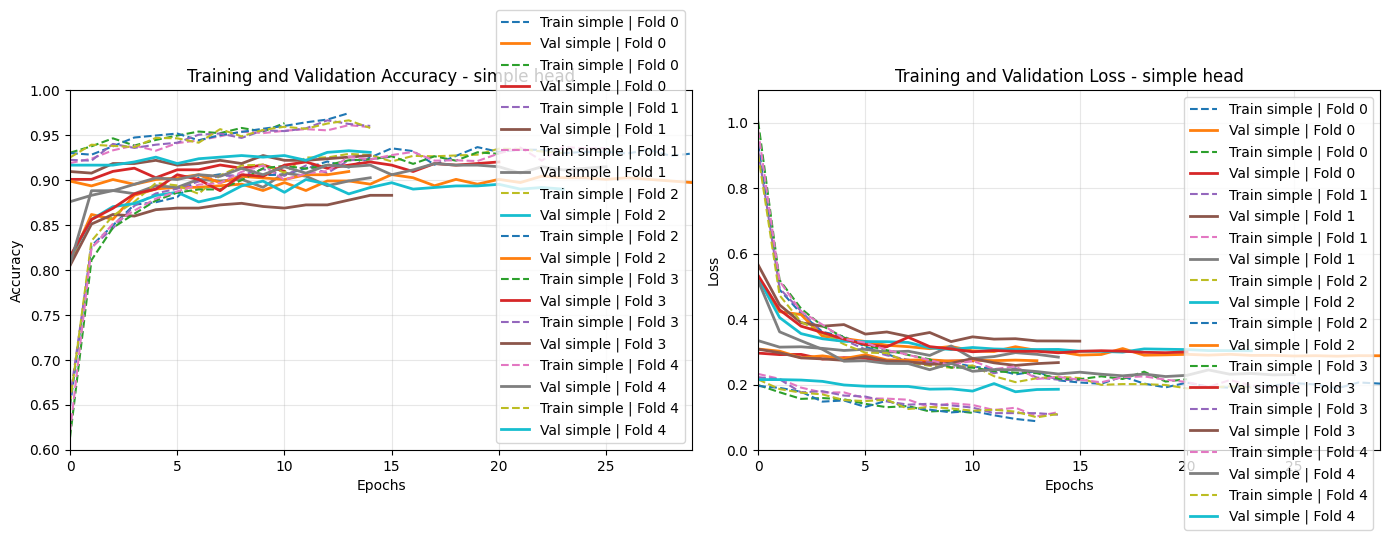

fixed head for mobilenetv2 light fine-tuning: simple


In [21]:
plot_cv_results(all_fold_histories, head_type=BEST_HEAD_TYPE)

print(f"fixed head for mobilenetv2 light fine-tuning: {BEST_HEAD_TYPE}")
